**Before starting this practical session**:

1. **No GPU is needed**: the models are tiny and train faster on the CPU. The default runtime type on Google Colab (CPU) is enough.
2. **Install the packages below**:

In [ ]:
! pip install lightning torchmetrics optuna

3. Run this code to suppress some messages and warnings that may be displayed.

In [2]:
import logging
logging.getLogger("lightning").setLevel(logging.ERROR)
logging.getLogger("lightning.pytorch.utilities.rank_zero").setLevel(logging.WARNING)
logging.getLogger("lightning.pytorch.accelerators.cuda").setLevel(logging.WARNING)
logger = logging.getLogger("lightning")
logger.propagate = False

import warnings
warnings.filterwarnings("ignore", ".*does not have many workers.*")
warnings.filterwarnings("ignore", ".*Missing logger folder.*")
warnings.filterwarnings("ignore", ".*GPU available but not used.*")
warnings.filterwarnings("ignore", "`isinstance\\(treespec, LeafSpec\\)` is deprecated.*")
warnings.filterwarnings("ignore", ".*is experimental.*")  # experimental features of Optuna

# Hyperparameter optimization

In the previous notebooks, we chose the learning rate, the number of hidden units or the number of epochs by hand.
These quantities are **hyperparameters**: unlike the **parameters** of the network (weights and biases), which are learned by gradient descent, hyperparameters are chosen *before* training.
Their values can have a large impact on the performance of the model.

**Hyperparameter optimization** (HPO) consists in finding the values of the hyperparameters that give the best performance on the **validation set**.
It is a hard problem: each evaluation of a set of hyperparameters is a full training run, which is expensive and noisy.

In this notebook, you will learn to:

1. distinguish the parameters and the hyperparameters of a model;
2. run a **grid search** and a **random search** by hand, and compare them with the same number of training runs;
3. use the [Optuna](https://optuna.org) library, which implements **Bayesian optimization** and the **early stopping of unpromising trials** (*pruning*);
4. follow a correct protocol with a training set, a validation set and a test set.

To keep things fast, we will work on a small two-dimensional toy dataset and a small multilayer perceptron.

## Setup

We fix the random seeds of Python, NumPy and PyTorch so that the results are reproducible.

In [3]:
import random
import time

import lightning as L
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import torch

SEED = 0


def set_seed(seed):
    """Set the random seeds of Python, NumPy and PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(SEED)
torch.set_num_threads(1)  # tiny models: one thread is faster and makes runs more reproducible

## Data

We generate the [*two moons*](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html) dataset: two interleaving half circles with some noise.
The task is a binary classification: to which moon does each point belong?

We split the data into three sets (60% / 20% / 20%), stratified by class and with a fixed seed:

* the **training set** is used to learn the parameters of the network (gradient descent);
* the **validation set** is used to choose the hyperparameters;
* the **test set** is used **only once, at the very end**, to estimate the performance of the final model on new data.

Why three sets? When we try many sets of hyperparameters and keep the best one on the validation set, the validation accuracy of this best model is optimistic: we selected it *because* it did well on these particular observations.
The test set has never been used to make any choice, so it gives an unbiased estimate of the performance.

In [4]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=1500, noise=0.3, random_state=SEED)

# 60% training, 20% validation, 20% test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, stratify=y_train_val, random_state=SEED
)

print(f"Training set:   {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set:       {X_test.shape[0]} samples")

Training set:   900 samples
Validation set: 300 samples
Test set:       300 samples


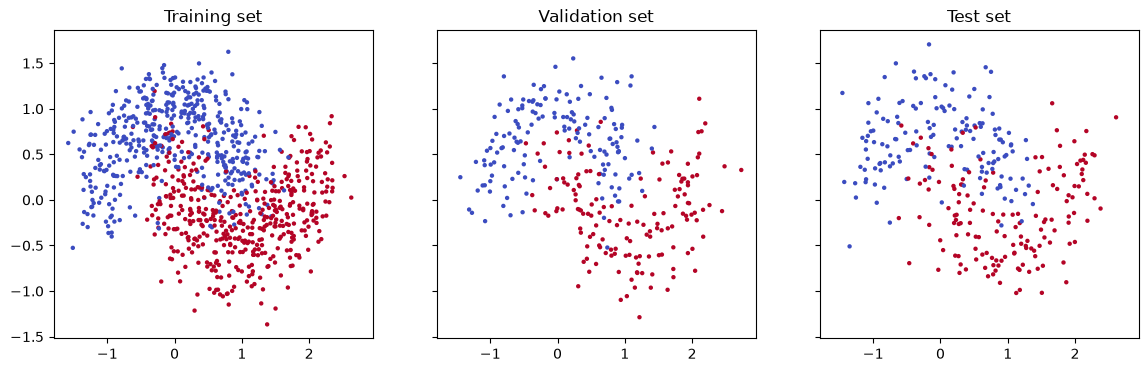

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)
for ax, (X_, y_, title) in zip(
    axes, [(X_train, y_train, "Training"), (X_val, y_val, "Validation"), (X_test, y_test, "Test")]
):
    ax.scatter(X_[:, 0], X_[:, 1], c=y_, cmap="coolwarm", s=10, edgecolors="none")
    ax.set_title(f"{title} set")
plt.show()

We convert the NumPy arrays into PyTorch tensors and create the datasets.

In [6]:
from torch.utils.data import DataLoader, TensorDataset


def to_dataset(X, y):
    return TensorDataset(
        torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)
    )


dataset_train = to_dataset(X_train, y_train)
dataset_val = to_dataset(X_val, y_val)
dataset_test = to_dataset(X_test, y_test)

## Model and training function

The model is a multilayer perceptron with one or more hidden layers and the ReLU activation function.
Its constructor takes the hyperparameters as arguments:

* `hidden_size`: the number of units in each hidden layer;
* `n_layers`: the number of hidden layers;
* `lr`: the learning rate $\eta$ of the Adam optimizer;
* `weight_decay`: the strength of the $L_2$ penalty on the weights.

In [7]:
from torchmetrics import Accuracy


class MLP(L.LightningModule):
    """Multilayer perceptron for binary classification.

    Parameters
    ----------
    hidden_size : int (default = 16)
        Number of units in each hidden layer.

    n_layers : int (default = 1)
        Number of hidden layers.

    lr : float (default = 1e-3)
        Learning rate.

    weight_decay : float (default = 0.0)
        Weight decay (L2 penalty).
    """

    def __init__(self, hidden_size=16, n_layers=1, lr=1e-3, weight_decay=0.0):
        super().__init__()
        self.save_hyperparameters()  # saved in self.hparams

        layers = []
        in_features = 2
        for _ in range(n_layers):
            layers += [torch.nn.Linear(in_features, hidden_size), torch.nn.ReLU()]
            in_features = hidden_size
        layers.append(torch.nn.Linear(in_features, 1))
        self.net = torch.nn.Sequential(*layers)

        self.loss = torch.nn.BCEWithLogitsLoss()
        self.accuracy_val = Accuracy(task="binary")
        self.accuracy_test = Accuracy(task="binary")

    def forward(self, x):
        return self.net(x).squeeze(1)  # logits

    def training_step(self, batch):
        x, y = batch
        return self.loss(self(x), y)

    def validation_step(self, batch):
        x, y = batch
        self.accuracy_val(self(x), y)
        self.log("accuracy_val", self.accuracy_val, on_epoch=True)

    def test_step(self, batch):
        x, y = batch
        self.accuracy_test(self(x), y)
        self.log("accuracy_test", self.accuracy_test, on_epoch=True)

    def configure_optimizers(self):
        return torch.optim.Adam(
            self.parameters(), lr=self.hparams.lr, weight_decay=self.hparams.weight_decay
        )

The `train_and_evaluate()` function trains a model **on the training set** with the given hyperparameters and returns its accuracy **on the validation set**.
This is the function that every HPO method will call: one call = one *trial*.

The optional `trial` argument will be used later with Optuna: after each epoch, the validation accuracy is reported to Optuna, which may decide to stop the trial early.
We implement this with a small Lightning callback.

> **Remark**: the models are tiny, so they train faster on the CPU than on a GPU (`accelerator="cpu"`).

In [8]:
class OptunaPruningCallback(L.Callback):
    """Report the validation accuracy to Optuna after each epoch and stop the trial if asked."""

    def __init__(self, trial):
        self.trial = trial

    def on_validation_epoch_end(self, trainer, pl_module):
        if trainer.sanity_checking:  # not a real epoch
            return
        epoch = trainer.current_epoch
        accuracy = trainer.callback_metrics["accuracy_val"].item()
        self.trial.report(accuracy, step=epoch)
        if self.trial.should_prune():
            raise optuna.TrialPruned(f"Pruned at epoch {epoch}")


def train_and_evaluate(lr, hidden_size, weight_decay=0.0, n_layers=1, n_epochs=40,
                       batch_size=64, seed=SEED, trial=None, return_model=False):
    """Train an MLP on the training set and return its validation accuracy.

    Parameters
    ----------
    lr, hidden_size, weight_decay, n_layers : hyperparameters of the model (see MLP).

    n_epochs : int (default = 40)
        Number of training epochs.

    batch_size : int (default = 64)
        Batch size.

    seed : int
        Random seed (initialization of the weights and order of the batches).

    trial : optuna.Trial or None (default = None)
        If provided, the validation accuracy is reported after each epoch and
        the trial can be pruned.

    return_model : bool (default = False)
        If True, also return the trained model and trainer.

    Returns
    -------
    accuracy_val : float
        Accuracy on the validation set at the end of training.
    """
    set_seed(seed)
    model = MLP(hidden_size=hidden_size, n_layers=n_layers, lr=lr, weight_decay=weight_decay)
    trainer = L.Trainer(
        max_epochs=n_epochs,
        accelerator="cpu",
        logger=False,                # no CSV logs
        enable_checkpointing=False,  # no checkpoints
        enable_progress_bar=False,
        enable_model_summary=False,
        num_sanity_val_steps=0,      # no validation step before training
        callbacks=[OptunaPruningCallback(trial)] if trial is not None else [],
    )
    trainer.fit(
        model,
        DataLoader(dataset_train, batch_size=batch_size, shuffle=True),
        DataLoader(dataset_val, batch_size=len(dataset_val)),
    )
    accuracy_val = trainer.callback_metrics["accuracy_val"].item()
    if return_model:
        return accuracy_val, model, trainer
    return accuracy_val

## Baseline: does the learning rate matter?

Let's train the same network (one hidden layer with 16 units) with three learning rates: a very small one, a reasonable one and a very large one.

In [9]:
for lr in [1e-5, 1e-2, 1.0]:
    accuracy_val = train_and_evaluate(lr=lr, hidden_size=16)
    print(f"Learning rate = {lr:<6g} -> validation accuracy = {accuracy_val:.2%}")

Learning rate = 1e-05  -> validation accuracy = 54.00%
Learning rate = 0.01   -> validation accuracy = 91.67%
Learning rate = 1      -> validation accuracy = 73.33%


With the same architecture and the same number of epochs, the validation accuracy goes from about 50% to about 90% just by changing the learning rate:

* with a **too small** learning rate, the weights barely move in 40 epochs and the model stays close to random guessing;
* with a **too large** learning rate, the optimization is unstable;
* in between, the model learns the shape of the two moons.

Choosing the hyperparameters by hand is tedious and does not scale.
Let's see how to search for good values automatically.

## Grid search

The simplest approach is the **grid search**: we choose a few values for each hyperparameter and try **every combination**.

We search over two hyperparameters:

* the learning rate $\eta \in \{10^{-4}, 10^{-3}, 10^{-2}, 10^{-1}\}$,
* the number of hidden units $\in \{4, 16, 64\}$,

which gives $4 \times 3 = 12$ training runs.

In [10]:
import itertools

lr_grid = [1e-4, 1e-3, 1e-2, 1e-1]
hidden_size_grid = [4, 16, 64]

start = time.time()
results_grid = []
for lr, hidden_size in itertools.product(lr_grid, hidden_size_grid):
    accuracy_val = train_and_evaluate(lr=lr, hidden_size=hidden_size)
    results_grid.append({"lr": lr, "hidden_size": hidden_size, "accuracy_val": accuracy_val})
results_grid = pd.DataFrame(results_grid)

print(f"Grid search: {len(results_grid)} trials in {time.time() - start:.0f} s")
results_grid.sort_values("accuracy_val", ascending=False).head()

Grid search: 12 trials in 24 s


,lr,hidden_size,accuracy_val
10,0.100,16,0.920000
7,0.010,16,0.916667
8,0.010,64,0.916667
11,0.100,64,0.916667
5,0.001,64,0.880000


A heatmap shows the validation accuracy of each combination.

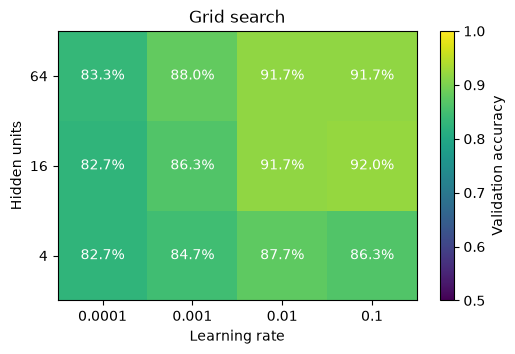

In [11]:
heatmap = results_grid.pivot(index="hidden_size", columns="lr", values="accuracy_val")

fig, ax = plt.subplots(figsize=(6, 3.5))
im = ax.imshow(heatmap.values, cmap="viridis", vmin=0.5, vmax=1.0, origin="lower")
ax.set_xticks(range(len(lr_grid)), [f"{lr:g}" for lr in lr_grid])
ax.set_yticks(range(len(hidden_size_grid)), hidden_size_grid)
ax.set_xlabel("Learning rate")
ax.set_ylabel("Hidden units")
for i in range(heatmap.shape[0]):
    for j in range(heatmap.shape[1]):
        ax.text(j, i, f"{heatmap.values[i, j]:.1%}", ha="center", va="center", color="w")
fig.colorbar(im, label="Validation accuracy")
ax.set_title("Grid search")
plt.show()

The learning rate clearly matters more than the number of hidden units here.

The main drawback of grid search is that the number of runs grows **exponentially** with the number of hyperparameters: with 5 hyperparameters and 5 values each, we would need $5^5 = 3125$ training runs.

## Random search

In a **random search**, each trial draws its hyperparameters at random from chosen distributions.
We use **the same budget as the grid search** (12 trials) and the same ranges:

* the learning rate is drawn **log-uniformly** between $10^{-4}$ and $10^{-1}$, i.e., its logarithm is uniform. A learning rate of $10^{-4}$ and one of $10^{-3}$ are as different as $10^{-2}$ and $10^{-1}$: a uniform distribution between $10^{-4}$ and $10^{-1}$ would almost never try small values;
* the number of hidden units is drawn log-uniformly between 4 and 64, then rounded to an integer.

In [12]:
n_trials = len(results_grid)  # same budget as the grid search
rng = np.random.default_rng(SEED)

start = time.time()
results_random = []
for _ in range(n_trials):
    lr = 10 ** rng.uniform(-4, -1)
    hidden_size = int(round(2 ** rng.uniform(2, 6)))  # between 4 and 64
    accuracy_val = train_and_evaluate(lr=lr, hidden_size=hidden_size)
    results_random.append({"lr": lr, "hidden_size": hidden_size, "accuracy_val": accuracy_val})
results_random = pd.DataFrame(results_random)

print(f"Random search: {len(results_random)} trials in {time.time() - start:.0f} s")
results_random.sort_values("accuracy_val", ascending=False).head()

Random search: 12 trials in 26 s


,lr,hidden_size,accuracy_val
2,0.027530,50,0.926667
3,0.006606,30,0.923333
8,0.038863,18,0.923333
4,0.004274,53,0.916667
11,0.010277,24,0.916667


## Grid search vs. random search

With the same budget, the grid tests only **4 distinct values of the learning rate** (each one 3 times, with different numbers of hidden units), whereas the random search tests **12 distinct values**.
The figure below shows the points tried by each method; the ticks along the horizontal axis are the values of the learning rate actually tested.

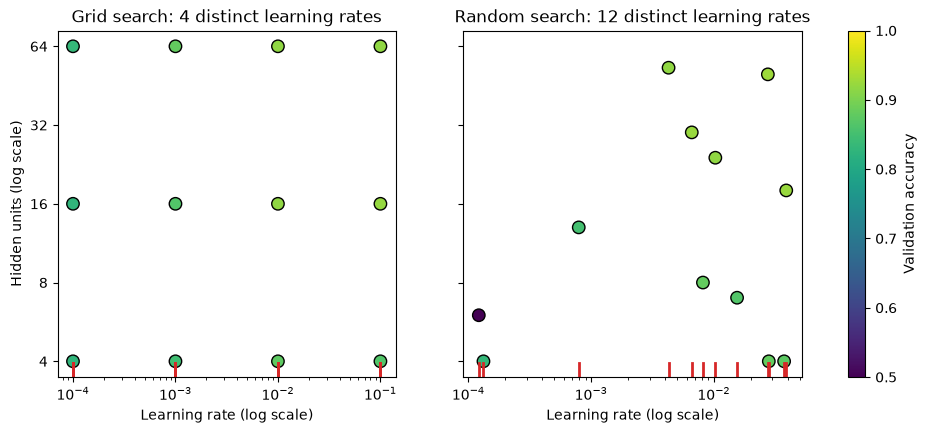

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (results, title) in zip(axes, [(results_grid, "Grid search"), (results_random, "Random search")]):
    sc = ax.scatter(results["lr"], results["hidden_size"], c=results["accuracy_val"],
                    cmap="viridis", vmin=0.5, vmax=1.0, s=80, edgecolors="k")
    # Projection of the points on the learning-rate axis
    for lr in results["lr"]:
        ax.axvline(lr, ymax=0.04, color="C3", lw=2)
    ax.set_xscale("log")
    ax.set_yscale("log", base=2)
    ax.set_yticks([4, 8, 16, 32, 64], [4, 8, 16, 32, 64])
    ax.set_xlabel("Learning rate (log scale)")
    ax.set_title(f"{title}: {results['lr'].nunique()} distinct learning rates")
axes[0].set_ylabel("Hidden units (log scale)")
fig.colorbar(sc, ax=axes, label="Validation accuracy")
plt.show()

We also plot the best validation accuracy found so far as a function of the number of trials.

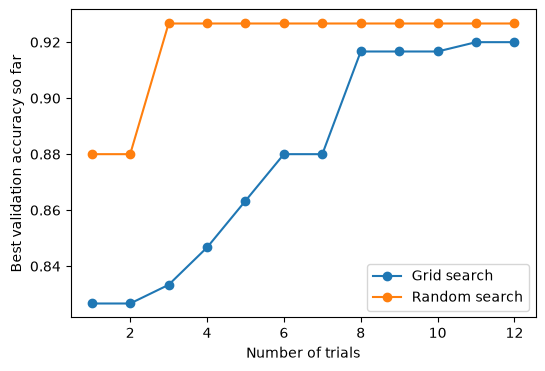

Best grid search:   92.00%
Best random search: 92.67%


In [14]:
fig, ax = plt.subplots(figsize=(6, 4))
for results, label in [(results_grid, "Grid search"), (results_random, "Random search")]:
    ax.plot(np.arange(1, len(results) + 1), results["accuracy_val"].cummax(), marker="o", label=label)
ax.set_xlabel("Number of trials")
ax.set_ylabel("Best validation accuracy so far")
ax.legend()
plt.show()

print(f"Best grid search:   {results_grid['accuracy_val'].max():.2%}")
print(f"Best random search: {results_random['accuracy_val'].max():.2%}")

On this tiny problem, both methods find good configurations and the difference between them is small: it can even change with the seed.
Note also that the order of the grid is arbitrary (here, it starts with the smallest learning rates), so the shape of its curve should not be over-interpreted.

The advantage of random search appears when there are **more hyperparameters**, only a few of which really matter (Bergstra and Bengio, 2012).
Here, the learning rate matters much more than the number of hidden units: the grid "wastes" two thirds of its budget on re-testing the same learning rates with different numbers of hidden units, which barely changes the result.
With 5 or 10 hyperparameters, a grid becomes impossibly large, while random search keeps testing a new value of *each* hyperparameter at every trial.

## Optuna: Bayesian optimization and pruning

Grid search and random search do not learn from past trials: the 12th trial is chosen without looking at the results of the first 11.
[Optuna](https://optuna.org) improves on both points:

* **Sampler (Bayesian optimization).** Its default sampler, TPE (*tree-structured Parzen estimator*), builds a cheap model of "which hyperparameters give a good validation accuracy" from the past trials, and chooses the next trial by balancing **exploitation** (regions that look good) and **exploration** (regions that have not been tried much). The first trials are random.
* **Pruner (early stopping of bad trials).** Many bad configurations are already obviously bad after a few epochs. After each epoch, our callback reports the validation accuracy to Optuna. The `MedianPruner` stops a trial when its accuracy is below the median accuracy of the previous trials at the same epoch. The saved time can be spent on more promising trials.

To use Optuna, we write an **objective function** that receives a `trial` object, asks it for values of the hyperparameters (`trial.suggest_float()`, `trial.suggest_int()`) and returns the validation accuracy.
We now search over **four** hyperparameters: the learning rate and the weight decay (log scale), the number of hidden units and the number of hidden layers.

In [15]:
def objective(trial):
    lr = trial.suggest_float("lr", 1e-4, 1e-1, log=True)
    hidden_size = trial.suggest_int("hidden_size", 4, 64, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True)
    n_layers = trial.suggest_int("n_layers", 1, 2)
    return train_and_evaluate(
        lr=lr, hidden_size=hidden_size, weight_decay=weight_decay, n_layers=n_layers, trial=trial
    )

We create a **study** that maximizes the objective, with a seeded TPE sampler and a median pruner:

* `n_startup_trials=5`: no pruning during the first 5 trials (there is nothing to compare with yet);
* `n_warmup_steps=10`: a trial is never pruned during its first 10 epochs (all models are bad at the very beginning).

We run 30 trials. Thanks to pruning, this costs much less than 30 full trainings.

In [16]:
optuna.logging.set_verbosity(optuna.logging.WARNING)  # do not print every trial

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=10),
)

start = time.time()
study.optimize(objective, n_trials=30)
print(f"Optuna: {len(study.trials)} trials in {time.time() - start:.0f} s")

states = pd.Series([t.state.name for t in study.trials]).value_counts()
print(f"Completed trials: {states.get('COMPLETE', 0)}, pruned trials: {states.get('PRUNED', 0)}")
print(f"Best validation accuracy: {study.best_value:.2%}")
print("Best hyperparameters:", study.best_params)

Optuna: 30 trials in 51 s
Completed trials: 18, pruned trials: 12
Best validation accuracy: 92.33%
Best hyperparameters: {'lr': 0.004430375245218269, 'hidden_size': 28, 'weight_decay': 0.00025766385746135923, 'n_layers': 2}


The `trials_dataframe()` method returns all the trials in a pandas DataFrame.

In [17]:
study.trials_dataframe()[
    ["number", "value", "params_lr", "params_hidden_size", "params_weight_decay", "params_n_layers", "state"]
].sort_values("value", ascending=False).head(10)

,number,value,params_lr,params_hidden_size,params_weight_decay,params_n_layers,state
0,0,0.923333,0.004430,28,0.000258,2,COMPLETE
27,27,0.923333,0.093815,33,0.000015,1,COMPLETE
20,20,0.923333,0.054620,39,0.000006,1,COMPLETE
21,21,0.923333,0.047634,43,0.000004,1,COMPLETE
28,28,0.923333,0.086471,19,0.000052,1,COMPLETE
22,22,0.923333,0.027948,23,0.000003,1,COMPLETE
25,25,0.920000,0.031315,26,0.000028,1,COMPLETE
3,3,0.920000,0.005060,52,0.000002,1,COMPLETE
26,26,0.916667,0.019594,61,0.000003,1,COMPLETE
10,10,0.913333,0.009160,55,0.000085,2,COMPLETE


Optuna provides several visualizations.
The optimization history shows the validation accuracy of each completed trial and the best value so far.

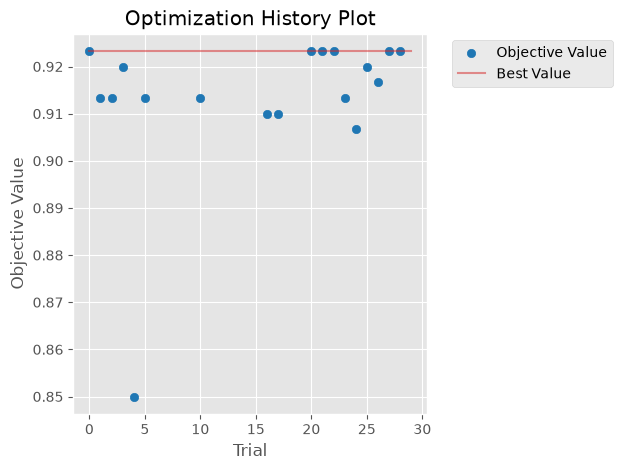

In [18]:
optuna.visualization.matplotlib.plot_optimization_history(study)
plt.show()

The intermediate values show the validation accuracy of each trial over the epochs.
The curves that stop early correspond to pruned trials.

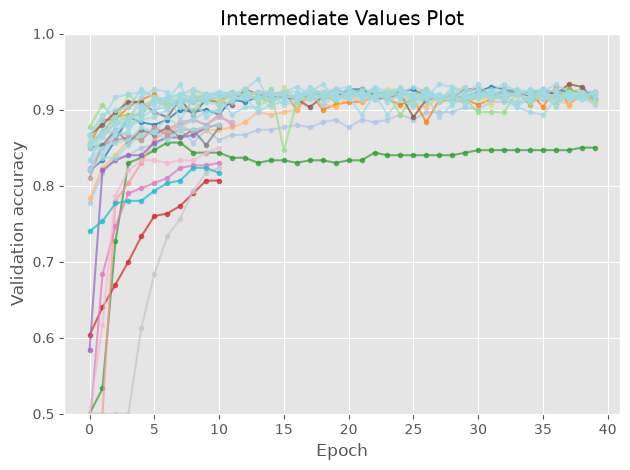

In [19]:
ax = optuna.visualization.matplotlib.plot_intermediate_values(study)
ax.get_legend().remove()  # one legend entry per trial is not readable
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation accuracy")
ax.set_ylim(0.5, 1.0)
plt.show()

Finally, Optuna can estimate the **importance** of each hyperparameter, i.e., how much of the variation of the validation accuracy among the trials it explains.

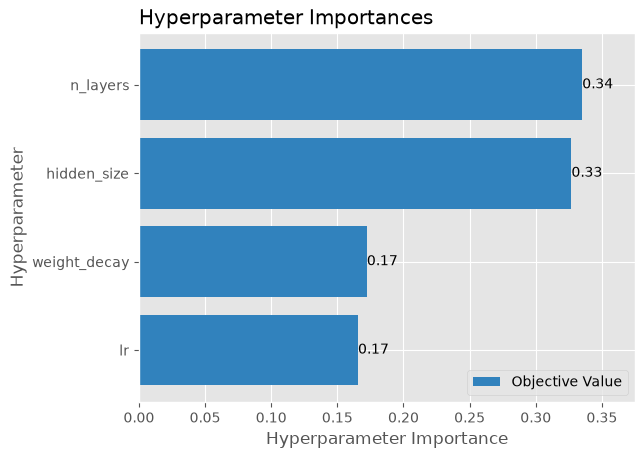

In [20]:
optuna.visualization.matplotlib.plot_param_importances(study)
plt.show()

Surprisingly, the learning rate may not come out on top here, although we saw at the beginning that it matters a lot.
This plot must be read with care: it is computed from the **completed trials only**.
Let's compare the learning rates of the completed and pruned trials.

In [21]:
study.trials_dataframe().groupby("state")["params_lr"].describe()[["count", "min", "50%", "max"]]

,count,min,50%,max
state,,,,
COMPLETE,18.0,0.000115,0.029632,0.093815
PRUNED,12.0,0.000226,0.002289,0.019385


The pruned trials have much smaller learning rates than the completed ones (compare the medians): the pruner stopped many trials that learned too slowly, and TPE then focused on good learning rates.
Among the completed trials, the learning rate is therefore almost always in a good range, and the small remaining differences (often less than one point of accuracy) are explained by the other hyperparameters.
With a few dozen trials concentrated in the good regions, the importances are a rough indication about *these trials*, not a general ranking of the hyperparameters.

## Final evaluation on the test set

We now choose the final model: the best configuration found by Optuna.
We retrain it on the training set and evaluate it **once** on the test set.

Until now, the test set has never been used: all the choices (which method, which hyperparameters) were made on the validation set.
If we had looked at the test accuracy to choose between configurations, the test set would have become a second validation set, and its accuracy would be optimistic too.

In [22]:
accuracy_val, best_model, best_trainer = train_and_evaluate(**study.best_params, return_model=True)
results_test = best_trainer.test(
    best_model, DataLoader(dataset_test, batch_size=len(dataset_test)), verbose=False
)
print(f"Validation accuracy: {accuracy_val:.2%}")
print(f"Test accuracy:       {results_test[0]['accuracy_test']:.2%}")

Validation accuracy: 92.33%
Test accuracy:       90.33%


The decision boundary of the final model separates the two moons.

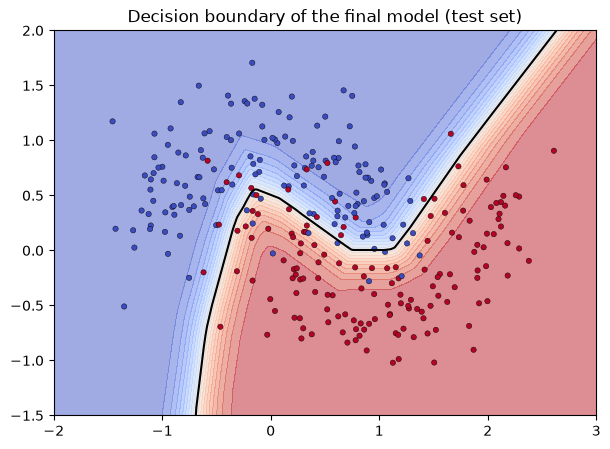

In [23]:
plt.style.use("default")  # the plots of Optuna switch matplotlib to the "ggplot" style

xx, yy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
best_model.eval()
with torch.no_grad():
    proba = torch.sigmoid(best_model(grid)).numpy().reshape(xx.shape)

fig, ax = plt.subplots(figsize=(7, 5))
ax.contourf(xx, yy, proba, levels=20, cmap="coolwarm", alpha=0.5)
ax.contour(xx, yy, proba, levels=[0.5], colors="k")
ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="coolwarm", s=15, edgecolors="k", linewidths=0.3)
ax.set_title("Decision boundary of the final model (test set)")
plt.show()

## Takeaways

* Start from known good default values for your architecture (e.g., Adam with a learning rate of $10^{-3}$).
* **Tune the learning rate first**: it is usually the most important hyperparameter. Sample it, as well as the weight decay, on a **log scale**.
* Prefer **random search** or a library such as **Optuna** to grid search, which does not scale with the number of hyperparameters.
* Choose the hyperparameters on the **validation set**, never on the test set. Report the performance on the test set **once**, at the end.
* Results are noisy: re-run the best configurations with a few different seeds before drawing conclusions.